# mpstab vs qibojit vs PauliPropagation.jl

Explore how the HSMPO surrogate compares, in time and accuracy, with

- **qibojit** (qibo's numba backend): exact statevector, or exact density matrix
  with noise. This is the reference every error is measured against.
- **PauliPropagation.jl**: Heisenberg-picture Pauli-sum propagation, truncated
  at `min_abs_coeff`.

in two scenarios: **exact** (noiseless) and **noisy** (depolarizing noise after
every gate plus ZZ crosstalk). All the plumbing lives in
[`frameworks.py`](frameworks.py); every simulator gets the same qibo circuit,
the same `mpstab.noise` events and the same observable.

**Launch** from the repository root:

```bash
uv run --with juliacall --with qibojit --with pandas --with jupyterlab \
    jupyter lab examples/notebooks/benchmarks/frameworks.ipynb
```

The first run downloads Julia and PauliPropagation.jl (a few minutes).

**Reading the timings**

- Times are wall-clock for one evaluation. mpstab: everything (Clifford/magic
  split, dressing, MPS evolution, sampling). qibojit: circuit execution and the
  expectation contraction (numba is warmed up first; building the Hamiltonian
  is not timed). PauliPropagation: the propagation, best of two runs so that
  Julia's per-circuit compilation is excluded (translating the circuit is not
  timed).
- Heavy settings grow fast: a 12-qubit density matrix takes ~30 s with
  qibojit, and noiseless PauliPropagation at small `min_abs_coeff` can take
  minutes past depth ~6. Increase sizes gradually.
- qibojit runs multithreaded (`THREADS` below); mpstab and PauliPropagation
  run on one core apart from BLAS.
- Noiseless mpstab is exact up to MPS truncation (`MAX_BOND`). Noisy mpstab is
  exact for zero and one fault and Monte Carlo beyond, so its error should sit
  around its `stderr` (dashed line). PauliPropagation is biased by its
  truncation: lower `MIN_ABS_COEFF` to trade time for accuracy.
- Both mpstab and PauliPropagation exploit the observable's light cone, so
  local observables on shallow circuits are their best case.


In [1]:
import numpy as np
import pandas as pd
from qibo import set_backend

import frameworks as fw

set_backend("numpy")  # mpstab's own qibo calls; qibojit is used as an object
pd.set_option("display.precision", 4)

[Qibo 0.3.6|INFO|2026-11-17 10:08:26]: Using numpy backend on /CPU:0


## Configuration

Edit and re-run from here.

In [2]:
THREADS = None  # qibojit threads; None = all cores

# Circuit family: fw.kicked_ising(n, depth) or fw.hardware_efficient(n, depth)
CIRCUIT = fw.kicked_ising

# Observable: a function of n returning a Pauli string or {pauli: coefficient}
OBSERVABLE = fw.local_z  # Z_0 Z_{n-1};  try fw.zz_chain for sum_i Z_i Z_i+1

# Noise: total depolarizing probability per qubit per gate, ZZ crosstalk angle
P_DEPOLARIZING, CROSSTALK = 0.005, 0.02

MPSTAB = dict(max_bond=None, light_cone=True)  # max_bond=None: no truncation
MPSTAB_NOISY = dict(MPSTAB, n_samples=1000, seed=0)
PP = dict(min_abs_coeff=1e-6)  # PauliPropagation truncation; lower = slower, more exact

In [3]:
jit = fw.qibojit_backend(THREADS)
pp = fw.PauliPropagation()  # installs + warms up Julia on first use
options = dict(qibojit=jit, pauli_propagation=pp, pp_options=PP)

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## Sanity check

One small case, every simulator side by side. All three should agree to
machine precision without noise; with noise PauliPropagation should still
match qibojit (up to `MIN_ABS_COEFF`) and mpstab within a few `stderr`.

In [4]:
n, depth = 8, 3
circuit = CIRCUIT(n, depth)
for events in ([], fw.noise_events(circuit, P_DEPOLARIZING, CROSSTALK)):
    rows = fw.compare(
        circuit, events, OBSERVABLE(n),
        mpstab_options=MPSTAB_NOISY if events else MPSTAB, **options,
    )
    print("noisy" if events else "exact")
    display(pd.DataFrame(rows).set_index("framework")[["value", "error", "time"]])

exact


,value,error,time
framework,,,
mpstab,0.3266,3.3307e-16,0.0042
qibojit,0.3266,0.0000e+00,0.0073
PauliPropagation,0.3266,8.8818e-16,0.0004


noisy


,value,error,time
framework,,,
mpstab,0.2404,2.6561e-04,0.4959
qibojit,0.2401,0.0000e+00,0.1711
PauliPropagation,0.2401,4.2835e-07,0.0009


## Exact simulation

### Width

At fixed depth the statevector doubles with every qubit, while mpstab and
PauliPropagation only see the observable's light cone.

n=8: mpstab 0.00318s  qibojit 0.00802s  PauliPropagation 0.000324s


n=12: mpstab 0.00426s  qibojit 0.0112s  PauliPropagation 0.000486s


n=16: mpstab 0.00556s  qibojit 0.0216s  PauliPropagation 0.000467s


n=20: mpstab 0.00668s  qibojit 0.108s  PauliPropagation 0.000506s


n=22: mpstab 0.00752s  qibojit 0.469s  PauliPropagation 0.000528s


n=24: mpstab 0.00797s  qibojit 2.17s  PauliPropagation 0.000451s


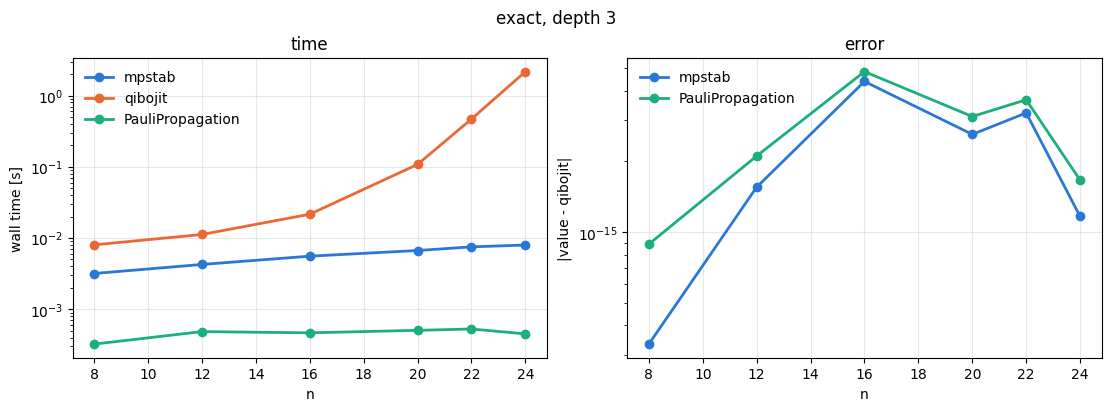

In [5]:
DEPTH = 3
SIZES = [8, 12, 16, 20, 22, 24]

exact_width = fw.sweep(
    ((n, CIRCUIT(n, DEPTH), [], OBSERVABLE(n)) for n in SIZES),
    label="n", mpstab_options=MPSTAB, **options,
)
fw.plot(exact_width, "n", f"exact, depth {DEPTH}");

In [6]:
exact_width.pivot(index="n", columns="framework", values=["time", "error"])

time                            error              \
framework PauliPropagation  mpstab qibojit PauliPropagation      mpstab   
n                                                                         
8                   0.0003  0.0032  0.0080       8.8818e-16  3.3307e-16   
12                  0.0005  0.0043  0.0112       2.1094e-15  1.5543e-15   
16                  0.0005  0.0056  0.0216       4.8295e-15  4.3854e-15   
20                  0.0005  0.0067  0.1080       3.1086e-15  2.6090e-15   
22                  0.0005  0.0075  0.4688       3.6637e-15  3.2196e-15   
24                  0.0005  0.0080  2.1686       1.6653e-15  1.1657e-15   

                   
framework qibojit  
n                  
8             0.0  
12            0.0  
16            0.0  
20            0.0  
22            0.0  
24            0.0

### Depth

At fixed width the light cone fills up with depth: the MPS bond dimension
grows for mpstab, the number of Pauli terms for PauliPropagation.

depth=1: mpstab 0.00191s  qibojit 0.0042s  PauliPropagation 0.000154s


depth=2: mpstab 0.00324s  qibojit 0.00763s  PauliPropagation 0.000169s


depth=3: mpstab 0.0043s  qibojit 0.0112s  PauliPropagation 0.000336s


depth=4: mpstab 0.00569s  qibojit 0.0146s  PauliPropagation 0.00482s


/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


depth=6: mpstab 0.00871s  qibojit 0.0224s  PauliPropagation 1.34s


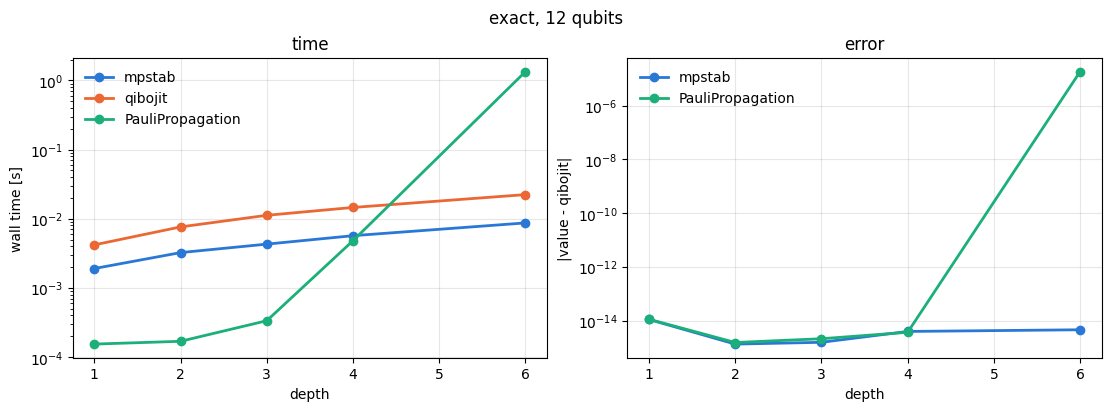

In [7]:
N = 12
DEPTHS = [1, 2, 3, 4, 6]  # noiseless PauliPropagation blows up past ~6 here

exact_depth = fw.sweep(
    ((d, CIRCUIT(N, d), [], OBSERVABLE(N)) for d in DEPTHS),
    label="depth", mpstab_options=MPSTAB, **options,
)
fw.plot(exact_depth, "depth", f"exact, {N} qubits");

In [8]:
exact_depth.pivot(index="depth", columns="framework", values=["time", "bond", "terms"])

time                             bond                 \
framework PauliPropagation  mpstab qibojit PauliPropagation mpstab qibojit   
depth                                                                        
1                   0.0002  0.0019  0.0042              NaN    1.0     NaN   
2                   0.0002  0.0032  0.0076              NaN    2.0     NaN   
3                   0.0003  0.0043  0.0112              NaN    2.0     NaN   
4                   0.0048  0.0057  0.0146              NaN    4.0     NaN   
6                   1.3393  0.0087  0.0224              NaN    8.0     NaN   

                     terms                 
framework PauliPropagation mpstab qibojit  
depth                                      
1                      4.0    NaN     NaN  
2                     64.0    NaN     NaN  
3                   1089.0    NaN     NaN  
4                  18212.0    NaN     NaN  
6                2384175.0    NaN     NaN

## Noisy simulation

### Width

qibojit now evolves a density matrix (4^n entries), so it stops at
`fw.QIBOJIT_MAX_QUBITS["density_matrix"]` qubits; beyond that there is no
reference and only the times are shown.

n=6: mpstab 0.0401s  qibojit 0.0551s  PauliPropagation 0.00019s


n=8: mpstab 0.046s  qibojit 0.116s  PauliPropagation 0.00019s


n=10: mpstab 0.0637s  qibojit 1.32s  PauliPropagation 0.000284s


n=11: mpstab 0.0557s  qibojit 8s  PauliPropagation 0.000207s


n=12: mpstab 0.0637s  qibojit 38.1s  PauliPropagation 0.00021s


n=16: mpstab 0.0858s  PauliPropagation 0.000332s


n=20: mpstab 0.106s  PauliPropagation 0.000309s


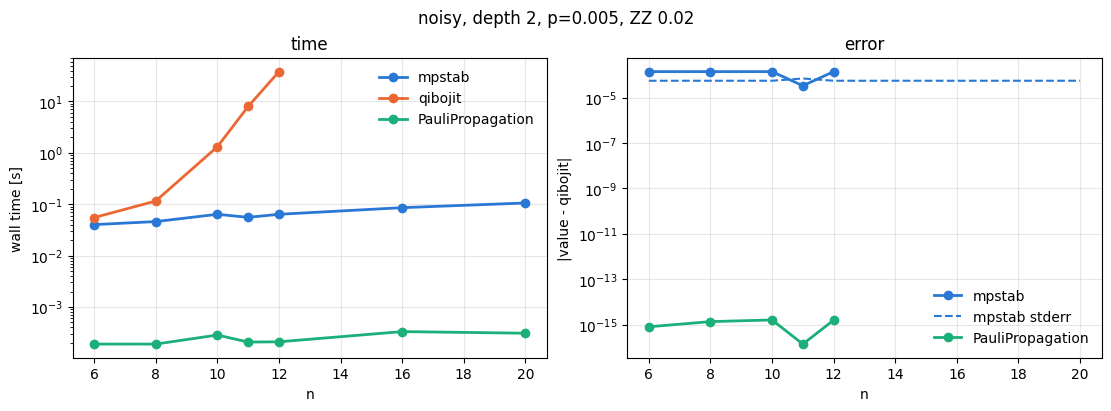

In [9]:
DEPTH = 2
SIZES = [6, 8, 10, 11, 12, 16, 20]

def noisy_case(n, depth):
    circuit = CIRCUIT(n, depth)
    return circuit, fw.noise_events(circuit, P_DEPOLARIZING, CROSSTALK), OBSERVABLE(n)

noisy_width = fw.sweep(
    ((n, *noisy_case(n, DEPTH)) for n in SIZES),
    label="n", mpstab_options=MPSTAB_NOISY, **options,
)
fw.plot(noisy_width, "n", f"noisy, depth {DEPTH}, p={P_DEPOLARIZING}, ZZ {CROSSTALK}");

### Depth

More gates mean more fault locations: the probability of two or more faults
grows, and with it mpstab's sampling error at fixed `n_samples`.

depth=1: mpstab 0.0106s  qibojit 0.682s  PauliPropagation 0.000167s


depth=2: mpstab 0.055s  qibojit 1.33s  PauliPropagation 0.000201s


depth=3: mpstab 0.583s  qibojit 1.98s  PauliPropagation 0.000989s


depth=4: mpstab 1.71s  qibojit 2.68s  PauliPropagation 0.0158s


/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


depth=6: mpstab 6.51s  qibojit 4s  PauliPropagation 1.5s


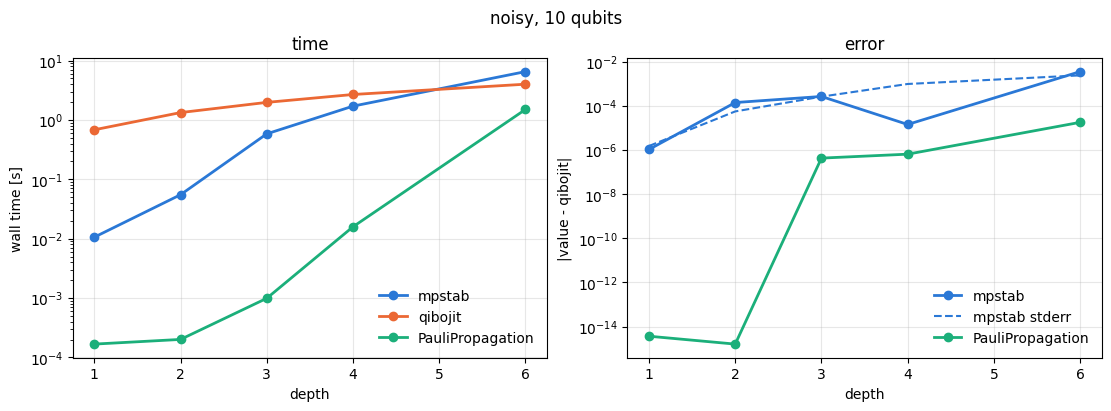

In [10]:
N = 10
DEPTHS = [1, 2, 3, 4, 6]

noisy_depth = fw.sweep(
    ((d, *noisy_case(N, d)) for d in DEPTHS),
    label="depth", mpstab_options=MPSTAB_NOISY, **options,
)
fw.plot(noisy_depth, "depth", f"noisy, {N} qubits");

In [11]:
noisy_depth[noisy_depth.framework == "mpstab"][
    ["depth", "value", "error", "stderr", "p_two_or_more", "patterns", "time"]
]

,depth,value,error,stderr,p_two_or_more,patterns,time
0,1,0.5471,1.0571e-06,1.5159e-06,0.0005,1.0,0.0106
3,2,0.2036,1.4079e-04,5.5805e-05,0.0056,60.0,0.0550
6,3,0.2404,2.6561e-04,2.6050e-04,0.0323,495.0,0.5828
9,4,0.2766,1.4314e-05,9.7702e-04,0.0893,876.0,1.7070
12,6,0.1849,3.5433e-03,2.3983e-03,0.3114,1318.0,6.5106


### Accuracy vs cost

The fair comparison for sampled and truncated methods: how much time does each
need to reach a given error? Sweep mpstab's `n_samples` and
PauliPropagation's `min_abs_coeff` on one case.

,framework,setting,time,error,stderr,terms
0,mpstab,1.0000e+02,0.4556,3.5124e-03,0.0028,NaN
1,mpstab,3.0000e+02,0.8177,3.4842e-04,0.0018,NaN
2,mpstab,1.0000e+03,1.6636,1.4314e-05,0.0010,NaN
3,mpstab,3.0000e+03,3.7054,7.3756e-05,0.0006,NaN
4,PauliPropagation,1.0000e-02,0.0008,2.3570e-02,NaN,192.0
5,PauliPropagation,1.0000e-03,0.0033,1.1433e-02,NaN,2669.0
6,PauliPropagation,1.0000e-04,0.0074,8.7797e-04,NaN,11178.0
7,PauliPropagation,1.0000e-05,0.0121,1.4895e-05,NaN,18368.0
8,PauliPropagation,1.0000e-06,0.0157,6.4600e-07,NaN,22955.0


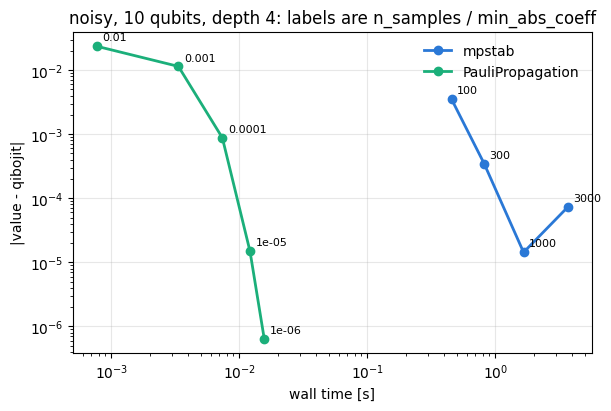

In [12]:
n, depth = 10, 4
circuit, events, observable = noisy_case(n, depth)
reference = fw.run_qibojit(jit, circuit, events, observable)["value"]

rows = []
for n_samples in [100, 300, 1000, 3000]:
    r = fw.run_mpstab_noisy(circuit, events, observable, **dict(MPSTAB_NOISY, n_samples=n_samples))
    rows.append(dict(framework="mpstab", setting=n_samples, time=r["time"],
                     error=abs(r["value"] - reference), stderr=r["stderr"]))
for threshold in [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    r = pp.run(circuit, events, observable, min_abs_coeff=threshold)
    rows.append(dict(framework="PauliPropagation", setting=threshold, time=r["time"],
                     error=abs(r["value"] - reference), terms=r["terms"]))
tradeoff = pd.DataFrame(rows)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
for name, group in tradeoff.groupby("framework", sort=False):
    ax.plot(group["time"], group["error"].clip(lower=1e-17), "o-",
            color=fw.COLORS[name], linewidth=2, label=name)
    for _, row in group.iterrows():
        ax.annotate(f"{row['setting']:g}", (row["time"], max(row["error"], 1e-17)),
                    textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="wall time [s]", ylabel="|value - qibojit|",
       title=f"noisy, {n} qubits, depth {depth}: labels are n_samples / min_abs_coeff")
ax.grid(alpha=0.3); ax.legend(frameon=False)
tradeoff

## Playground

Any circuit and observable: build the events with `fw.noise_events` (or by
hand with `mpstab.noise.PauliChannel` / `CoherentRotation`) and pass them to
`fw.compare`.

In [13]:
circuit = fw.hardware_efficient(12, 4, seed=1)
events = fw.noise_events(circuit, p=0.002, crosstalk=0.0)
observable = {"ZZ" + "I" * 10: 1.0, "I" * 5 + "XX" + "I" * 5: -0.5}
pd.DataFrame(fw.compare(circuit, events, observable, mpstab_options=MPSTAB_NOISY, **options))

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


,framework,n,gates,error,value,time,stderr,patterns,p_two_or_more,min_fidelity,terms
0,mpstab,12,96,1.0820e-04,0.4736,2.6972,0.0002,586.0,0.0162,1.0,NaN
1,qibojit,12,96,0.0000e+00,0.4737,33.8165,NaN,NaN,NaN,NaN,NaN
2,PauliPropagation,12,96,4.4409e-16,0.4737,0.0003,NaN,NaN,NaN,NaN,120.0
